# Fig. 6h: selection biases of the spike sorters for each neuron type (evoked model)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel h of the paper: for each neuron type of the evoked biophysical ground truth (same types and order as fig6g.ipynb) and each spike sorter, the probability of the type among the sorted single-units divided by its probability in the ground truth (ratio, "odds"). Source data and svg are saved in figures/8_source_data/fig6h/.

**method (as in the paper's notebook fig6_G_H_selection_bias.ipynb)**
* ground truth: the 1,836 neurons of the evoked simulation; sorting: the 1-hour sortings of the evoked simulation of six sorters (Kilosort 4, 3, 2.5, 2, Kilosort, Herdingspikes), generated on a Tesla V100 GPU (`v100_sortings/`, the sortings of the paper)
* single-units: units labelled "good" by Kilosort (Kilosort 2 to 4); Kilosort and Herdingspikes have no such label and all their units are used
* each sorted unit takes the synapse class and the etype of its best matching ground truth neuron (agreement score with delta_time = 1.3 ms) and the layer of the unit's contact
* ratio = (count of the type among the sorted units / number of sorted units) / (count of the type in the ground truth / number of ground truth neurons)
* p-value: two-sided Fisher exact test of the 2 x 2 table (type, other types) x (ground truth, sorter), without correction for multiple tests, as in the paper
* in the figure: red bold, increased probability (ratio >= 1, p < 0.05); blue bold, reduced probability (ratio <= 1, p < 0.05); black, p >= 0.05

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from scipy.stats import fisher_exact
from src.nodes import utils
from src.nodes.analysis.features import features as feat

# paths
GT_PATH = "dataset/00_raw/ground_truth_npx_evoked"
SORTINGS_PATH = ("v100_sortings/0_silico/4_spikesorting_stimulus_test_neuropixels_8-1-24__8slc_80f_360r_50t_200ms_1_smallest_fiber_gids/"
                 "0fcb7709-b1e9-4d84-b056-5801f20d55af/")     # sortings of the evoked simulation (Tesla V100, 1 hour, 20 kHz)
SORTERS = {"ks4": "SortingKS4_full", "ks3": "SortingKS3_full", "ks2.5": "SortingKS2_5_full", "ks2": "SortingKS2_full", "ks": "SortingKS_full", "hs": "SortingHerdingspikes_full"}
DT = 1.3     # ms

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the ground truth and the sortings

In [2]:
%%time

SortingTrue = si.load_extractor(GT_PATH)

# neuron types of the ground truth (as in fig6g.ipynb)
df_gt = feat.get_unit_features(SortingTrue)[["synapse", "layer", "etype"]]
unique_type = df_gt.drop_duplicates().sort_values(by=["synapse", "layer"])
count_gt = feat.count_unit_type(df_gt, unique_type)

# type of the sorted single-units of each sorter
count_by_sorter = {}
for sorter, folder in SORTERS.items():
    Sorting = si.load_extractor(SORTINGS_PATH + folder)

    # synapse class and etype of the best matching ground truth neuron; layer of the sorted unit
    df_sorted = feat.get_sorted_unit_features(Sorting, SortingTrue, DT)
    df_sorted["layer"] = utils.standardize_layers(Sorting.get_property("layer"))

    # single-units
    if "KSLabel" in Sorting.get_property_keys():
        df_sorted = df_sorted[Sorting.get_property("KSLabel") == "good"]
    count_by_sorter[sorter] = feat.count_unit_type(df_sorted[["synapse", "layer", "etype"]], unique_type)
    print(sorter, "single-units:", len(df_sorted))

ks4 single-units: 354


ks3 single-units: 384


ks2.5 single-units: 184


ks2 single-units: 458


ks single-units: 1337


hs single-units: 304
CPU times: user 13.3 s, sys: 93.9 ms, total: 13.3 s
Wall time: 13.3 s


## Ratio and p-value of each neuron type and sorter

In [3]:
def get_odds(count_sorting, count_gt):
    """probability of each type after sorting divided by its probability in the ground truth"""
    return (count_sorting["count"].values / count_sorting["count"].sum()) / (count_gt["count"].values / count_gt["count"].sum())

def get_pvalues(count_sorting, count_gt):
    """two-sided Fisher exact test of each type (type vs other types) between the ground truth and the sorter"""
    pvalues = []
    for ix in range(len(count_gt)):
        table = [[count_gt["count"].iloc[ix], count_sorting["count"].iloc[ix]],
                 [count_gt["count"].sum() - count_gt["count"].iloc[ix], count_sorting["count"].sum() - count_sorting["count"].iloc[ix]]]
        pvalues.append(fisher_exact(table, alternative="two-sided")[1])
    return np.array(pvalues)

rows = []
for sorter, count_sorting in count_by_sorter.items():
    odds, pvalues = get_odds(count_sorting, count_gt), get_pvalues(count_sorting, count_gt)
    for ix in range(len(count_gt)):
        # direction of the bias: increased if the ratio is >= 1, reduced if it is <= 1 (reduced when equal to 1, as in the paper's code)
        direction = -1 if odds[ix] <= 1 else 1
        rows.append(dict(type_index=ix, synapse_class=count_gt["type"].iloc[ix][0], layer=count_gt["type"].iloc[ix][1], etype=count_gt["type"].iloc[ix][2],
                         sorter=sorter, count_ground_truth=int(count_gt["count"].iloc[ix]), count_sorted=int(count_sorting["count"].iloc[ix]),
                         ratio=odds[ix], p_value=pvalues[ix], direction=direction))
df = pd.DataFrame(rows)
df["bias"] = np.where(df["p_value"] < 0.05, np.where(df["direction"] == 1, "increased", "reduced"), "same")
display(df.head(8).round(3))
print(df.groupby("sorter", sort=False)["bias"].value_counts().unstack(fill_value=0))

,type_index,synapse_class,layer,etype,sorter,count_ground_truth,count_sorted,ratio,p_value,direction,bias
0,0,EXC,L2/3,cADpyr,ks4,342,29,0.440,0.000,-1,reduced
1,1,EXC,L4,cADpyr,ks4,286,31,0.562,0.001,-1,reduced
2,2,EXC,L5,cADpyr,ks4,389,168,2.240,0.000,1,increased
3,3,EXC,L6,cADpyr,ks4,658,99,0.780,0.004,-1,reduced
4,4,INH,L1,cACint,ks4,2,1,2.593,0.411,1,same
5,5,INH,L1,cNAC,ks4,4,1,1.297,0.586,1,same
6,6,INH,L2/3,dNAC,ks4,4,0,0.000,1.000,-1,same
7,7,INH,L2/3,cNAC,ks4,6,0,0.000,0.598,-1,same


bias    increased  reduced  same
sorter                          
ks4             1        3    31
ks3             1        3    31
ks2.5           3        2    30
ks2             2        3    30
ks              2        2    31
hs              1        2    32


## Plot, same as the paper's panel h

In [4]:
RED, BLUE = "#ed1c24", "#3f4fa3"     # colours of the increased and reduced probabilities in the paper figure (approximate)
GREY = (0.7, 0.7, 0.7)

def plot_source_data(df: pd.DataFrame):
    """Ratio of the probability of each neuron type after spike sorting to its probability in the ground truth (numbers), by spike sorter
    (columns) and neuron type (rows, same order as fig6g); red bold: increased probability (p < 0.05), blue bold: reduced probability (p < 0.05)"""

    sorters = list(dict.fromkeys(df["sorter"]))
    n_types = df["type_index"].nunique()
    fig, ax = plt.subplots(figsize=(1.8, 5.7))
    ax.imshow(np.zeros((n_types, len(sorters))), cmap="binary", aspect="auto", rasterized=True)
    for j, sorter in enumerate(sorters):
        d = df[df["sorter"] == sorter].sort_values("type_index")
        for i, (ratio, bias) in enumerate(zip(d["ratio"], d["bias"])):
            color = {"increased": RED, "reduced": BLUE}.get(bias, "k")
            ax.text(j, i, f"{np.round(ratio, 1)}", ha="center", va="center", color=color, weight="bold" if bias != "same" else None)

    # aesthetics
    ax.set_xticks(range(len(sorters)), sorters, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(n_types), [])
    ax.set_xlabel("Spike sorters")
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.01))
    ax.spines["left"].set_position(("axes", -0.02))

    # title and legend
    ax.text(0.5, 1.15, "Selection biases", transform=ax.transAxes, ha="center", va="bottom", fontweight="bold", fontsize=7)
    ax.text(0.5, 1.095, "Probability after spike sorting divided\nby probability in ground truth (ratio)", transform=ax.transAxes, ha="center", va="bottom", fontsize=5.5)
    for k, (label, color, tcolor) in enumerate([("Increased probability (p<0.05)", RED, RED), ("Same probability (p>=0.05)", GREY, "k"), ("Reduced probability (p<0.05)", BLUE, BLUE)]):
        y = 1.06 - 0.02 * k
        ax.add_patch(plt.Rectangle((0.0, y - 0.006), 0.12, 0.012, transform=ax.transAxes, color=color, clip_on=False))
        ax.text(0.16, y - 0.001, label, transform=ax.transAxes, ha="left", va="center", fontsize=5.5, color=tcolor)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 309 ms, sys: 8 ms, total: 317 ms
Wall time: 317 ms


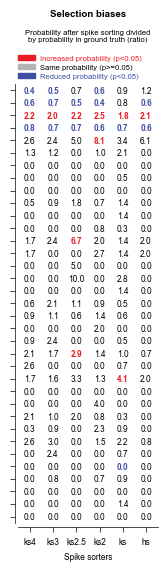

In [5]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig6h", exist_ok=True)
plt.savefig("figures/8_source_data/fig6h/fig6h.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig6h/fig6h.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 47.9 ms, sys: 0 ns, total: 47.9 ms
Wall time: 47.9 ms


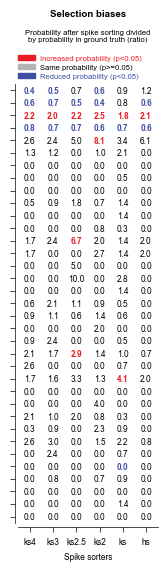

In [6]:
%%time

df = pd.read_excel("figures/8_source_data/fig6h/fig6h.xlsx")
fig, ax = plot_source_data(df)